## Лабораторная работа 1
### Разработка моделей  

_Коломзаров Никита, ИВТ-42_

_Цели работы:_  
* Изучение основ построения моделей в Python с использованием
NumPy и Matplotlib  
* Изучение приёмов построения моделей с графическим
пользовательским интерфейсом (GUI) на основе Tkinter или PyQt/
PySide  
* Получение практических навыков разработки моделей с
вычислениями, визуализацией и интерактивными приложениями  

### Задание 1 
Построить модель груза на невесомой нерастяжимой нити и попадающей в нее пулей. Получить трехмерные графики
зависимостей изменения угла отклонения груза, от различных параметров.  
Вариант 2: Угол(Длина подвеса, масса груза)  

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import tkinter as tk

In [68]:
m = 0.03
g = 9.8
v = 300

l_min, l_max = 0.5, 2
m_min, m_max = 5, 10
step = 100
l = np.linspace(l_min, l_max, step)
M = np.linspace(m_min, m_max, step)
L_grid, M_grid = np.meshgrid(l, M)
alpha_rad = np.arccos(1 - m**2 * v**2 / (2 * (M_grid + m)**2 * g * L_grid))
alpha_deg = np.rad2deg(alpha_rad)

Text(0.5, 0.92, 'α(l, M), m = 0.03, v = 300')

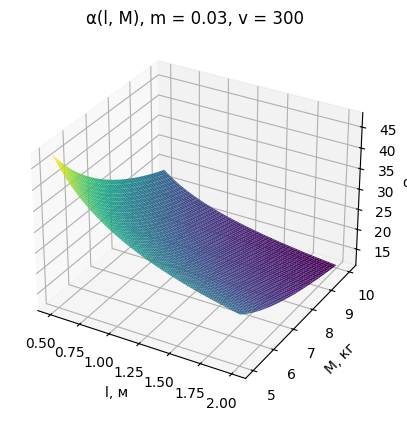

In [69]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(L_grid, M_grid, alpha_deg, cmap='viridis')
ax.set_xlabel('l, м')
ax.set_ylabel('M, кг')
ax.set_zlabel('α, °')
ax.set_title(f'α(l, M), m = {m}, v = {v}')

### Задание 2
Разработайте программу с GUI, которая позволяет пользователю выбрать
одну из тригонометрических функций и построить ее график.

In [93]:
import tkinter as tk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure
import numpy as np

root = tk.Tk()
root.title("Выбор функции")

selected_func = tk.StringVar(value=np.sin)
rb_sin = tk.Radiobutton(root, text="sin(x)", variable=selected_func, value='sin')
rb_cos = tk.Radiobutton(root, text="cos(x)", variable=selected_func, value='cos')
rb_tan = tk.Radiobutton(root, text="tan(x)", variable=selected_func, value='tan')
rb_sin.pack()
rb_cos.pack()
rb_tan.pack()

x_min_label = tk.Label(root, text="X_min")
x_min_label.pack()
x_min_entry = tk.Entry(root)
x_min_entry.pack()
x_max_label = tk.Label(root, text="X_max")
x_max_label.pack()
x_max_entry = tk.Entry(root)
x_max_entry.pack()

def error_screen(label):
        error = tk.Tk()
        error.title("ERROR")
        error_label = tk.Label(error, text=label)
        error_label.pack()
        error.mainloop()

def on_plot_button_click():
    func = selected_func.get()
    x_min = x_min_entry.get()
    x_max = x_max_entry.get()
    try:
        x_min = float(x_min)
        x_max = float(x_max)
    except ValueError:
        error_screen("Значение x должно быть числом")
        return
    if (x_min >= x_max):
        error_screen("x_min не должно превышать x_max")
        return
    x = np.linspace(x_min, x_max, 1000)
    ax.clear()
    ax.grid()
    ax.set_title(func + '(x)')
    match (func):
        case 'sin': func = np.sin
        case 'cos': func = np.cos
        case 'tan': func = np.tan
    y = func(x)
    ax.plot(x, y)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    canvas.draw()

button = tk.Button(root, text="Показать значение", command=on_plot_button_click)
button.pack()

fig = Figure(figsize=(5, 4), dpi=100)
ax = fig.add_subplot(111)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid()
canvas = FigureCanvasTkAgg(fig, master=root)
canvas_widget = canvas.get_tk_widget()
canvas_widget.pack(fill=tk.BOTH, expand=True)
root.mainloop()

Пользовательский интерфейс программы и примеры использования приведены на рисунках ниже

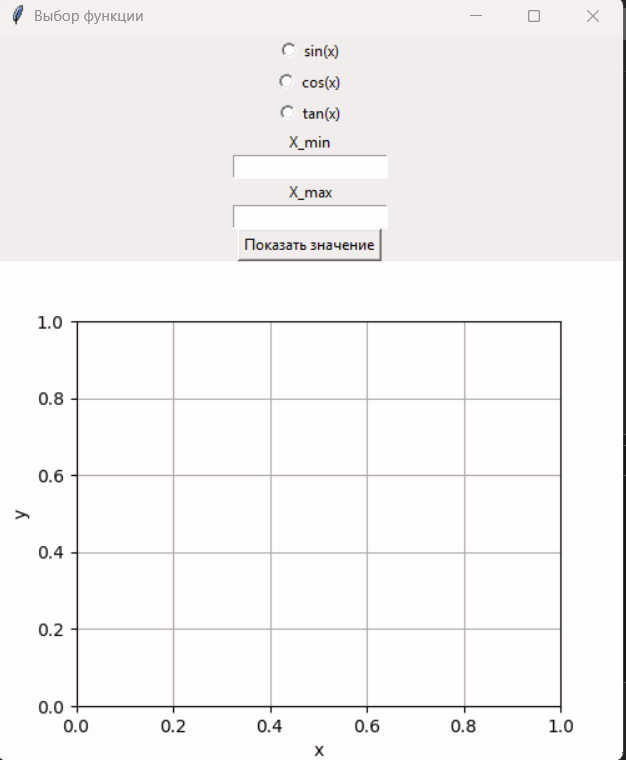  

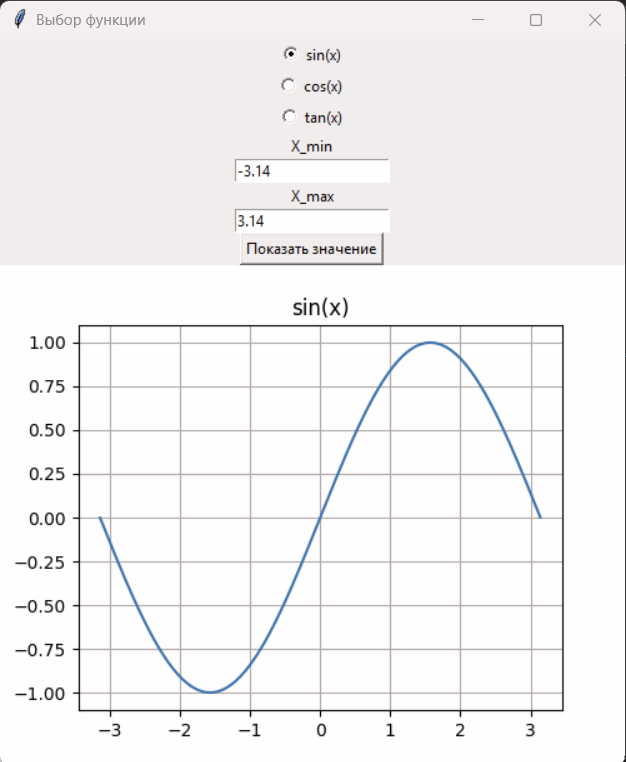  

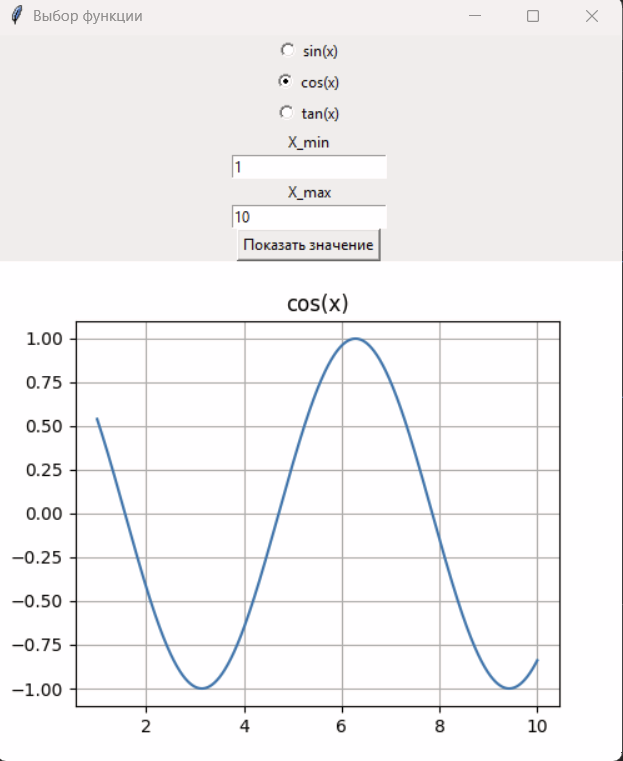  

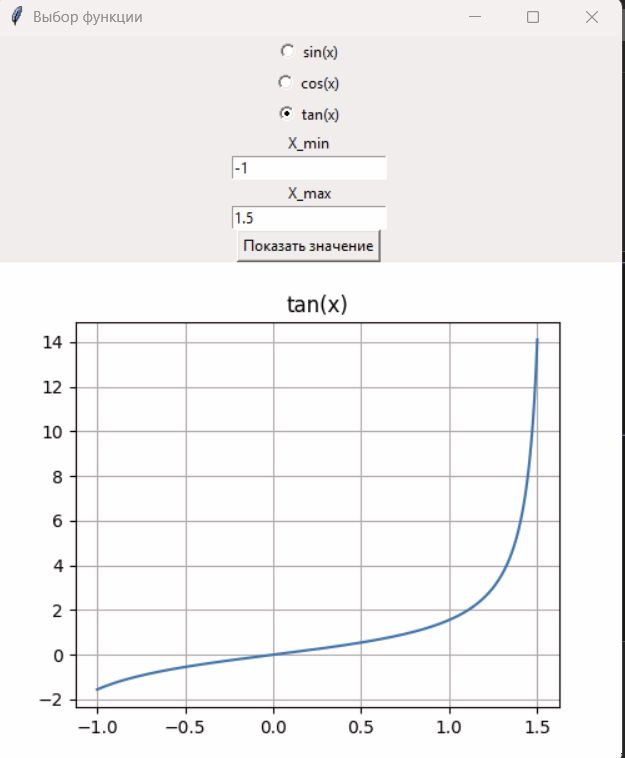  

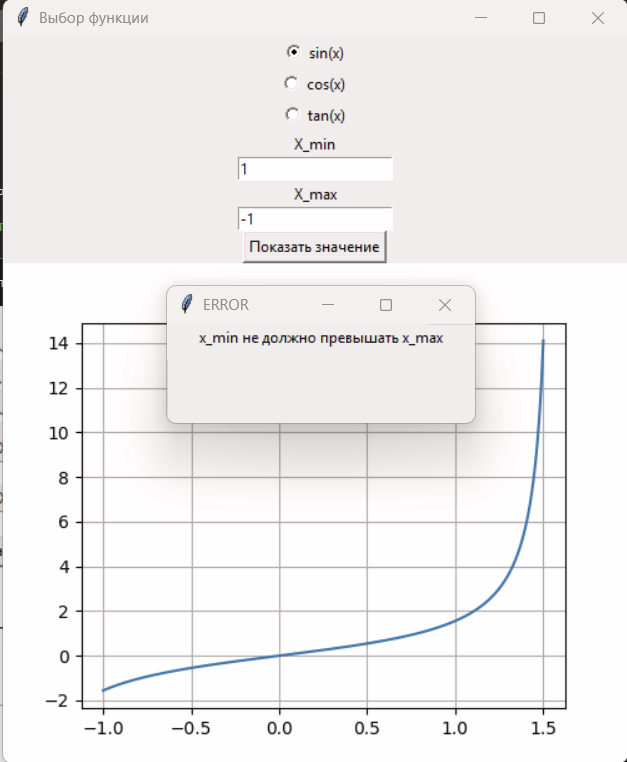  


### Задание 3

Разработайте модель с применением GUI по примеру 2.
Исходными данными для модели являются:
* диаметр отверстия (мм);
* толщина металла (мм);
* мощность лазера (Вт);
* плотность металла (кг/м3).

In [110]:
import tkinter as tk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure
import numpy as np

T_pl = None
T    = None
H1   = None
H2   = None
H3   = None

D    = 30   # mm
L    = 100  # mm
W    = 1000 # J / s
r    = 7800 # kg / m3

def error_screen(label):
    error = tk.Tk()
    error.title("ERROR")
    error_label = tk.Label(error, text=label)
    error_label.pack()
    error.mainloop()

def time_screen(t_mod):
    tscreen = tk.Tk()
    tscreen.title("Время моделирования")
    tscreen_label = tk.Label(tscreen, text=f"Модельное время: {t_mod} секунд")
    tscreen_label.pack()
    tscreen.mainloop()

def calculate():
    try:
        T_pl, T, H1, H2, H3 = map(float, map(tk.Entry.get, (t_1, t_2, h_1, h_2, h_3)))
        D, L, W, r = map(float, map(tk.Entry.get, (d_entry, l_entry, w_entry, r_entry)))
    except ValueError:
        error_screen("Параметры заданы неверно")
        return
    h = (T_pl - T) * H1 + H2 + H3
    S = np.pi * (D * 1e-3 / 2)**2
    t_mod = L * 1e-3 * h * S * r / W
    tk.Label(root, text=f"Модельное время: {"__" if t_mod is None else t_mod} секунд").pack()
    t = np.linspace(0, t_mod, 1000, endpoint=True)
    ax.clear()
    ax.grid()
    l = W * t / (h * S * r)
    ax.plot(t, l)
    ax.set_xlabel("t, с")
    ax.set_ylabel("l, мм")
    canvas.draw()
    time_screen(t_mod)
    

root = tk.Tk()
root.title("Модель лазера")

tk.Label(root, text="Тепловые параметры").pack()
tk.Label(root, text="-"*20).pack()
tk.Label(root, text=f"Температура плавления, К").pack()
t_1 = tk.Entry(root)
t_1.pack()
tk.Label(root, text=f"Исходная температура, К").pack()
t_2 = tk.Entry(root)
t_2.pack()
tk.Label(root, text=f"Удельная теплоемкость h1 Дж / кг / К").pack()
h_1 = tk.Entry(root)
h_1.pack()
tk.Label(root, text=f"Удельная теплота плавления h2 Дж / кг").pack()
h_2 = tk.Entry(root)
h_2.pack()
tk.Label(root, text=f"Удельная теплота парообразования h3 Дж / кг").pack()
h_3 = tk.Entry(root)
h_3.pack()
tk.Label(root, text="-"*20).pack()
tk.Label(root, text="D [mm]").pack()
d_entry = tk.Entry(root)
d_entry.pack()
tk.Label(root, text="L [mm]").pack()
l_entry = tk.Entry(root)
l_entry.pack()
tk.Label(root, text="W [Watt]").pack()
w_entry = tk.Entry(root)
w_entry.pack()
tk.Label(root, text="r [kg / m^3]").pack()
r_entry = tk.Entry(root)
r_entry.pack()
button_t = tk.Button(root, text="Применить параметры и вычислить", command=calculate)
button_t.pack()

fig = Figure(figsize=(5, 4), dpi=100)
ax = fig.add_subplot(111)
ax.set_xlabel("t, с")
ax.set_ylabel("l, мм")
ax.grid()
canvas = FigureCanvasTkAgg(fig, master=root)
canvas_widget = canvas.get_tk_widget()
canvas_widget.pack(fill=tk.BOTH, expand=True)
root.mainloop()

Пользовательский интерфейс программы и примеры использования приведены на рисунках ниже  

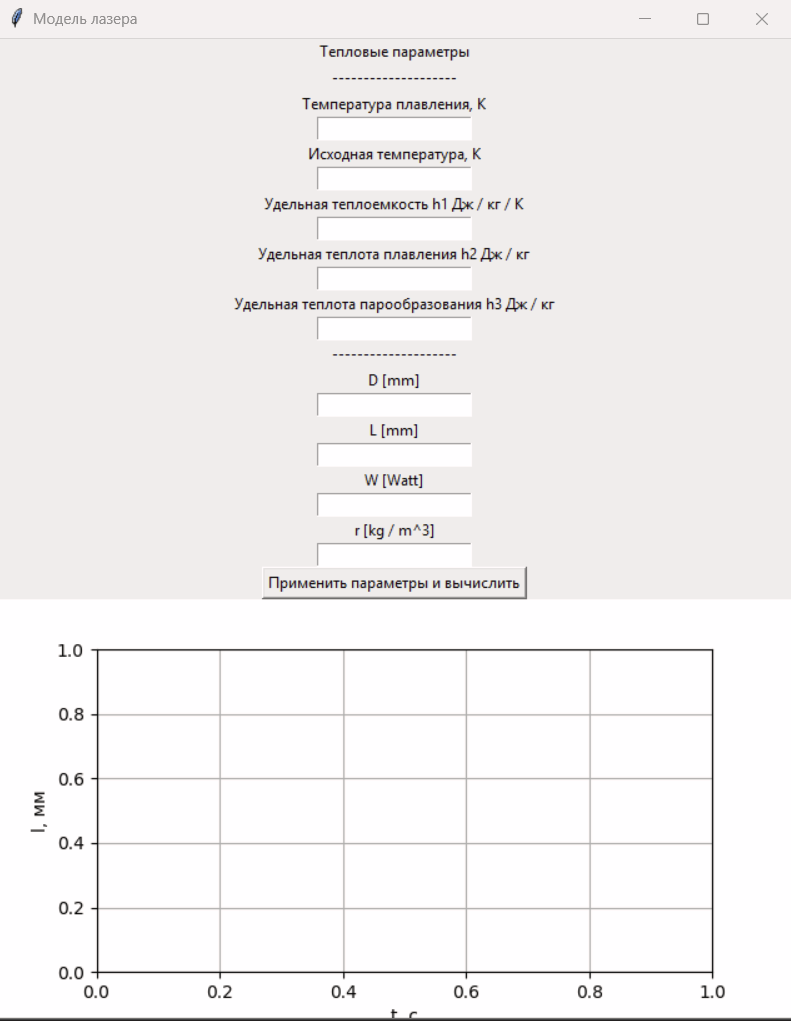  

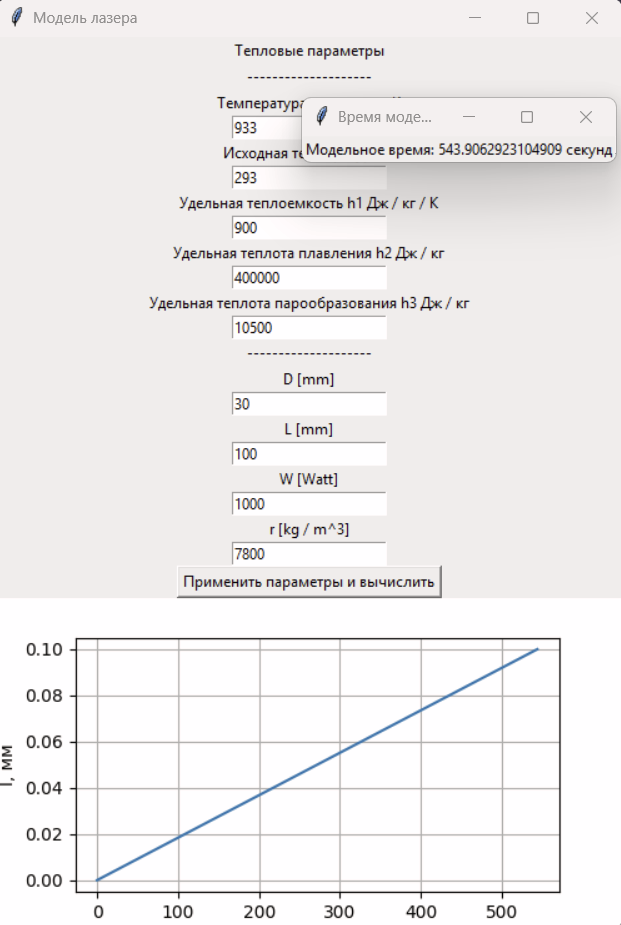  
